# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [3]:
import pandas as pd
import numpy as np

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [4]:
import numpy as np

def mae(actual, predicted):
    return np.mean(np.abs(np.array(actual) - np.array(predicted)))

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [5]:
def sse(actual, predicted):
    return np.sum((np.array(actual) - np.array(predicted)) ** 2)
def mse(actual, predicted):
    return sse(actual, predicted) / len(actual)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [6]:
def rmse(actual, predicted):
    return np.sqrt(mse(actual, predicted))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [7]:
def mape(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return 100 * np.mean(np.abs((actual - predicted) / actual))

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [8]:
def r2(actual, predicted):
    actual = np.array(actual)
    sst = np.sum((actual - actual.mean()) ** 2)
    return 1 - sse(actual, predicted) / sst

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [9]:
import pandas as pd

ads = pd.read_csv('advertising.csv', index_col=0)
ads.head().round(2)

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [10]:
ads.info()

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB


In [11]:
X = ads.drop(columns='Sales')
y = ads['Sales']

print(X.shape, y.shape)

(200, 3) (200,)


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [12]:
ads.corr().round(2)

,TV,Radio,Newspaper,Sales
TV,1.00,0.05,0.06,0.78
Radio,0.05,1.00,0.35,0.58
Newspaper,0.06,0.35,1.00,0.23
Sales,0.78,0.58,0.23,1.00


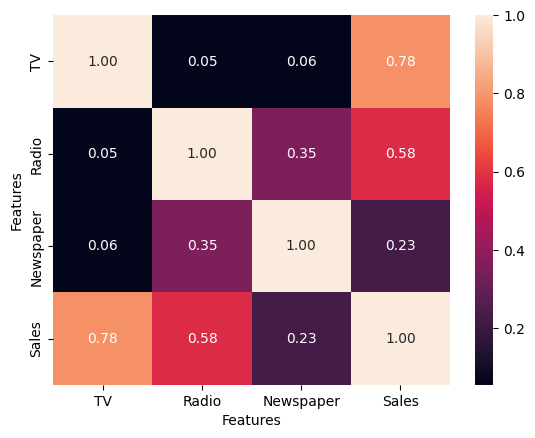

In [13]:
import seaborn as sea
import matplotlib.pyplot as mat

sea.heatmap(ads.corr(), annot=True, fmt='.2f')
mat.xlabel('Features')
mat.ylabel('Features')
mat.show()

TV has the strongest correlation with Sales (0.78), followed by Radio (0.58). Newspaper has a weaker correlation (0.23).

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(134, 3) (66, 3)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [15]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)


In [16]:
print('b0:', round(linear_model.intercept_, 2))
print(pd.Series(linear_model.coef_, index=X.columns).round(2))

b0: 14.02
TV           3.97
Radio        2.88
Newspaper   -0.07
dtype: float64


#### 2.5 Evaluate created model with above functions

In [17]:
print('MAE:', round(mae(y_test, linear_predictions), 2))
print('SSE:', round(sse(y_test, linear_predictions), 2))
print('MSE:', round(mse(y_test, linear_predictions), 2))
print('RMSE:', round(rmse(y_test, linear_predictions), 2))
print('MAPE:', round(mape(y_test, linear_predictions), 2))
print('R2:', round(r2(y_test, linear_predictions), 2))

MAE: 1.24
SSE: 229.19
MSE: 3.47
RMSE: 1.86
MAPE: 18.64
R2: 0.85


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [18]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    LinearRegression(), X_train, y_train, cv=10, scoring='r2'
)

print('Mean R2:', round(scores.mean(), 2))

Mean R2: 0.9


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [19]:
X_train_small = X_train.drop(columns='Newspaper')
X_test_small = X_test.drop(columns='Newspaper')

small_scaler = StandardScaler()
X_train_small = small_scaler.fit_transform(X_train_small)
X_test_small = small_scaler.transform(X_test_small)

small_model = LinearRegression()
small_model.fit(X_train_small, y_train)

small_predictions = small_model.predict(X_test_small)

In [20]:
comparison = pd.DataFrame({
    'Model': ['All features', 'Without Newspaper'],
    'MSE': [mse(y_test, linear_predictions), mse(y_test, small_predictions)],
    'R2': [r2(y_test, linear_predictions), r2(y_test, small_predictions)]
})

comparison.round(2)

,Model,MSE,R2
0,All features,3.47,0.85
1,Without Newspaper,3.46,0.85


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [21]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=1)
lasso_model.fit(X_train_scaled, y_train)
lasso_predictions = lasso_model.predict(X_test_scaled)

print('Lasso MSE:', round(mse(y_test, lasso_predictions), 2))

Lasso MSE: 4.91


#### 3.2 Ridge regression

In [22]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1)
ridge_model.fit(X_train_scaled, y_train)
ridge_predictions = ridge_model.predict(X_test_scaled)

print('Ridge MSE:', round(mse(y_test, ridge_predictions), 2))

Ridge MSE: 3.48


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [23]:
from sklearn.linear_model import ElasticNet

elastic_model = ElasticNet(alpha=1, l1_ratio=0.5)
elastic_model.fit(X_train_scaled, y_train)

elastic_predictions = elastic_model.predict(X_test_scaled)

print('Elastic Net MSE:', round(mse(y_test, elastic_predictions), 2))

Elastic Net MSE: 6.84


#### 3.4 Make conclusions

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [24]:
def accuracy(actual, predicted):
    return np.mean(np.array(actual) == np.array(predicted))

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [25]:
def precision(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    return tp / (tp + fp) if tp + fp else 0

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [26]:
def recall(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    tp = np.sum((actual == 1) & (predicted == 1))
    fn = np.sum((actual == 1) & (predicted == 0))
    return tp / (tp + fn) if tp + fn else 0

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [27]:
def f1(actual, predicted):
    p = precision(actual, predicted)
    r = recall(actual, predicted)

    return 2 * p * r / (p + r) if p + r else 0

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [28]:
diabetes = pd.read_csv('diabetes.csv')

for column in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    diabetes[column] = diabetes[column].replace(0, np.nan)
    diabetes[column] = diabetes[column].fillna(diabetes[column].mean())

diabetes.head().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00,155.55,33.6,0.63,50,1
1,1,85.0,66.0,29.00,155.55,26.6,0.35,31,0
2,8,183.0,64.0,29.15,155.55,23.3,0.67,32,1
3,1,89.0,66.0,23.00,94.00,28.1,0.17,21,0
4,0,137.0,40.0,35.00,168.00,43.1,2.29,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

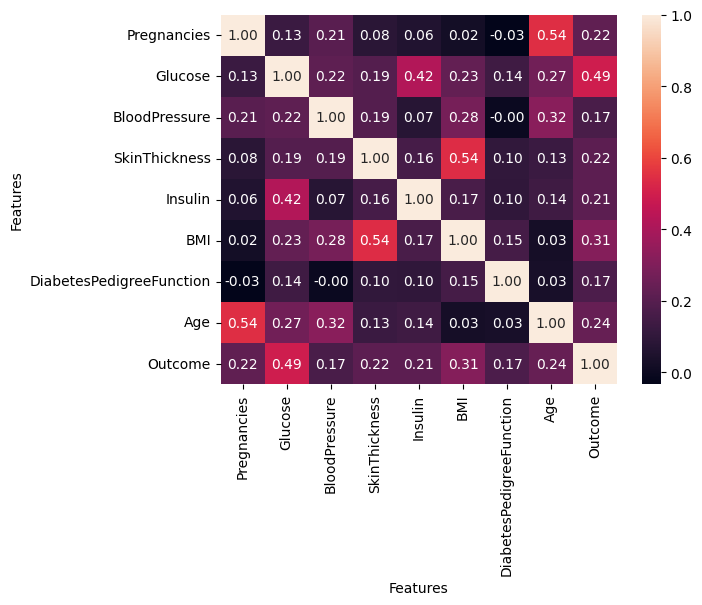

In [29]:
import seaborn as sea
import matplotlib.pyplot as mat

sea.heatmap(diabetes.corr(), annot=True, fmt='.2f')
mat.xlabel('Features')
mat.ylabel('Features')
mat.show()

Glucose has the strongest positive correlation with Outcome. BMI and Age also have positive correlations, but they are weaker.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_diabetes = diabetes.drop(columns='Outcome')
y_diabetes = diabetes['Outcome']

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diabetes, y_diabetes, test_size=0.33, random_state=17
)

scaler_d = StandardScaler()
X_train_d_scaled = scaler_d.fit_transform(X_train_d)
X_test_d_scaled = scaler_d.transform(X_test_d)

print(X_train_d.shape, X_test_d.shape)

(514, 8) (254, 8)


#### 2.4 Fit logistic regression model, generate predictions

In [31]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_d_scaled, y_train_d)
logistic_predictions = logistic_model.predict(X_test_d_scaled)

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [32]:
from sklearn.metrics import confusion_matrix

print('Confusion matrix:')
print(confusion_matrix(y_test_d, logistic_predictions))
print('Accuracy:', round(accuracy(y_test_d, logistic_predictions), 2))
print('Precision:', round(precision(y_test_d, logistic_predictions), 2))
print('Recall:', round(recall(y_test_d, logistic_predictions), 2))
print('F1:', round(f1(y_test_d, logistic_predictions), 2))

Confusion matrix:
[[145  20]
 [ 43  46]]
Accuracy: 0.75
Precision: 0.7
Recall: 0.52
F1: 0.59


#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.83


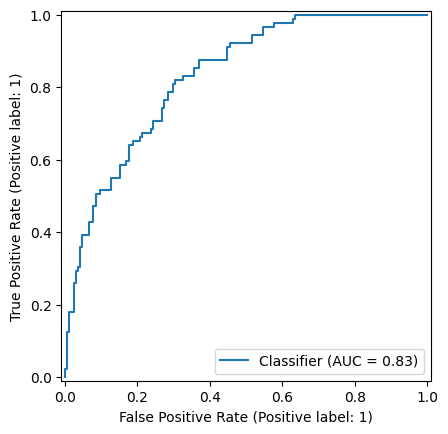

In [33]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as mat

logistic_probs = logistic_model.predict_proba(X_test_d_scaled)[:, 1]

print('AUC:', round(roc_auc_score(y_test_d, logistic_probs), 2))

RocCurveDisplay.from_predictions(y_test_d, logistic_probs)
mat.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [34]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_d_scaled,
    y_train_d,
    cv=10,
    scoring='accuracy'
)

print('Mean accuracy:', round(scores.mean(), 2))

Mean accuracy: 0.76


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [35]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_d_scaled, y_train_d)
tree_predictions = tree_model.predict(X_test_d_scaled)

#### 3.2 Evaluate created model with above functions

In [36]:
print('Confusion matrix:')
print(confusion_matrix(y_test_d, tree_predictions))
print('Accuracy:', round(accuracy(y_test_d, tree_predictions), 2))
print('Precision:', round(precision(y_test_d, tree_predictions), 2))
print('Recall:', round(recall(y_test_d, tree_predictions), 2))
print('F1:', round(f1(y_test_d, tree_predictions), 2))

Confusion matrix:
[[135  30]
 [ 28  61]]
Accuracy: 0.77
Precision: 0.67
Recall: 0.69
F1: 0.68


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.75


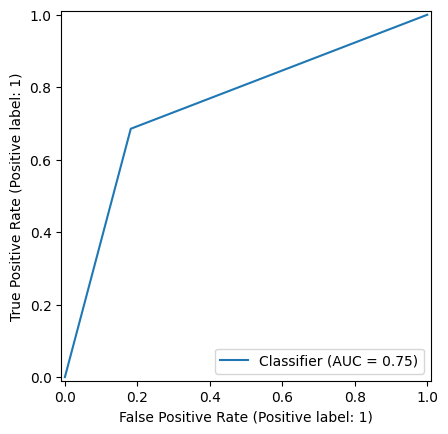

In [37]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as mat

tree_probs = tree_model.predict_proba(X_test_d_scaled)[:, 1]
print('AUC:', round(roc_auc_score(y_test_d, tree_probs), 2))
RocCurveDisplay.from_predictions(y_test_d, tree_probs)
mat.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [38]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(
    DecisionTreeClassifier(random_state=42),
    X_train_d_scaled,
    y_train_d,
    cv=10,
    scoring='accuracy'
)

print('Mean accuracy:', round(scores.mean(), 2))

Mean accuracy: 0.73


Linear Regression gives an MSE of 3.47. Removing Newspaper slightly improves it to 3.46, so this feature doesn't seem very useful. Ridge gives a similar result (3.48), while Lasso (4.91) and Elastic Net (6.84) perform worse with alpha=1.

#### 3.5 Make conclusions

Decision Tree has slightly better test accuracy (0.77) and recall (0.69). Logistic Regression has better AUC (0.83) and cross-validation accuracy (0.76). Logistic Regression seems more consistent overall, while Decision Tree identifies more positive cases.